<center>
<h1><b> TP3: Prompt Engineering </b>
<h1><b>Classification tasks : Sentiment Analysis </b>
</center>

# Objectives

- Present LLMs as an effective tool to tackle classification problems.
- Illustrate prompt engineering for sentiment analysis.
- Build and evaluate LLMs on broader classification tasks.


# Preparer l'environement

1. Prendre VS Code, je vais créer un un nouveau dossier que je vais appeler **SMA_TokPr** et ouvrir le terminal.
2. **UV** install: utiliser la la commande, pour MacOS: ```curl -LsSf https://astral.sh/uv/install.sh | sh```  sous Windows utiliser la commande dans le powerShell: `powershell -ExecutionPolicy ByPass -c "irm https://astral.sh/uv/install.ps1 | iex"`. Après instalation de UV quittez et relancez VScode.
3. dans le terminal de VsCode utiliser la commande ` uv init ` pour initialiser le projet. Donc ça nous permet de générer la structure des projets notamment avec le fichier **.toml** .
4. créer un environnement virtuel. Avec la commande: ` uv venv ` .
3. autoriser PowerSell à exécuter les scripts avec cette commande dans le terminal: ` Set-ExecutionPolicy -ExecutionPolicy RemoteSigned -Scope Process ` . puis aller au dosssier **Scripts** et activer les scripts avec la commande:  ` .\.venv\Scripts\activate `.
5.  cree un notebook **prompttoken.ipynb** pour le test puis choisir un noyaux(le kernel) et tester avec `print("Bonjour")` .
  

7. installer la bib tiktoken avec ` uv add tiktoken `

In [1]:
import tiktoken

In [2]:
tokenizer=tiktoken.encoding_for_model("gpt-4o")


In [3]:
print(tokenizer.name)


o200k_base


In [4]:
tokenizer=tiktoken.get_encoding("o200k_base")

In [5]:
prompt="Vous êtes un expert en marketing digital. C'est quoi un digital marketer ? "

In [6]:
tokens=tokenizer.encode(prompt)

In [7]:
print(tokens)


[29038, 34077, 537, 8333, 469, 6686, 7058, 13, 363, 6616, 33399, 537, 7058, 95641, 1423, 220]


In [8]:
print(len(tokens))


16


In [9]:
for token in tokens:
    t=tokenizer.decode_single_token_bytes(token).decode("utf-8")
    print(t,end='|')

Vous| êtes| un| expert| en| marketing| digital|.| C|'est| quoi| un| digital| marketer| ?| |

# Utilisation des llm

8. installer la dépendance langchain avec la commande: ` uv add langchain ` et installer langchain-openai ` uv add langchain-openai `

In [10]:
from langchain_openai import ChatOpenAI
from dotenv.ipython import load_dotenv

aller dans openaiplatform et generer une api key puis cree un fichier .env qui contient la cle gnere

In [11]:
load_dotenv(override=True)

True

In [12]:
llm=ChatOpenAI(model="gpt-4o", temperature=0)


**apel** a llm

In [ ]:
resp=llm.invoke(input=[{"role":"system","content":"Vous êtes un expert en marketing digital"},{"role":"user","content":"C'est quoi un digital marketer ?"}])

In [18]:
from IPython.display import Markdown

In [ ]:
print(display(Markdown(resp.content)))

# ollama llm

# dans power shell instaler ollama et utiliser la commande ` ollama run qwen3.5:cloud `

dans le terminal vscode telecharger ollama ` uv add langchain-ollama `

In [14]:
from langchain_ollama import ChatOllama

In [15]:
llm2 = ChatOllama(model="gemma4:31b-cloud", temperature=0)

In [16]:
resp2=llm2.invoke(input=[{"role":"system","content":"Vous êtes un expert en marketing digital"},{"role":"user","content":"C'est quoi un digital marketer ?"}])

In [22]:
display(Markdown(resp2.content))

En tant qu'expert, je vais vous répondre de manière précise et structurée.

Pour faire simple : **un digital marketer (ou responsable marketing numérique) est le chef d'orchestre de la visibilité d'une marque sur internet.**

Son objectif principal est d'attirer des clients potentiels (leads), de les convertir en acheteurs et de les fidéliser, en utilisant les canaux digitaux. Contrairement au marketing traditionnel (TV, radio, affichage), le marketing digital permet de **mesurer précisément** chaque action et de **cibler** des audiences très spécifiques.

Voici les piliers fondamentaux de son métier :

### 1. Les leviers d'acquisition (Comment attirer du monde ?)
Le digital marketer utilise plusieurs canaux pour générer du trafic :
*   **SEO (Search Engine Optimization) :** L'art d'optimiser un site pour qu'il apparaisse dans les premiers résultats gratuits de Google.
*   **SEA (Search Engine Advertising) :** La publicité payante sur les moteurs de recherche (ex: Google Ads).
*   **Social Media Marketing :** Gérer la présence sur Facebook, Instagram, TikTok, LinkedIn pour créer une communauté et engager l'audience.
*   **Email Marketing :** Envoyer des campagnes ciblées pour nourrir la relation client (lead nurturing).
*   **Content Marketing :** Créer des articles de blog, des vidéos ou des podcasts pour apporter de la valeur et asseoir son expertise.

### 2. L'analyse et la donnée (Le "Data-Driven")
C'est ce qui différencie le marketing digital du reste. Un digital marketer ne travaille pas au "feeling", mais avec des chiffres. Il utilise des outils comme **Google Analytics** pour répondre à des questions comme :
*   D'où viennent mes visiteurs ?
*   Pourquoi quittent-ils le site sans acheter ?
*   Quel canal rapporte le plus de chiffre d'affaires ?

### 3. L'optimisation de la conversion (CRO)
Attirer 1 million de personnes sur un site ne sert à rien si personne n'achète. Le digital marketer travaille sur l'**UX (Expérience Utilisateur)** et le **CRO (Conversion Rate Optimization)** pour rendre le parcours d'achat le plus fluide possible (simplification du formulaire, boutons d'appel à l'action efficaces, etc.).

---

### Les différents profils de Digital Marketers
Le domaine est devenu si vaste qu'on trouve aujourd'hui deux types de profils :

1.  **Le "T-Shaped" Marketer (Généraliste) :** Il a des connaissances de base dans tous les domaines cités plus haut, mais une expertise très profonde dans un seul (par exemple, il sait tout faire, mais il est un "crack" en SEO).
2.  **Le Spécialiste :** Il se concentre sur une seule niche. On parlera alors de *Traffic Manager*, *Community Manager*, *SEO Specialist* ou *CRM Manager*.

### En résumé
Si on devait résumer le rôle du digital marketer en une phrase : **C'est la personne qui utilise la technologie et la donnée pour délivrer le bon message, à la bonne personne, au bon moment et sur le bon canal.**

In [29]:
import pandas as pd
import numpy as np
import json
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from IPython.display import display, Markdown

CSV_PATH = r"C:\Users\Admin\OneDrive\Desktop\dataset_imdb\IMDBDataset.csv"  

df = pd.read_csv(CSV_PATH, sep=None, engine="python")

df.columns = [str(col).strip().lower() for col in df.columns]

if not {"sentiment", "review"}.issubset(df.columns):
    raise ValueError(
        f"Colonnes attendues : sentiment et review. "
        f"Colonnes détectées : {df.columns.tolist()}"
    )

df = df[["review", "sentiment"]].dropna().copy()

df["review"] = df["review"].astype(str).str.strip()

display(df.head())
print("Nombre de lignes :", len(df))
print("Colonnes :", df.columns.tolist())

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


Nombre de lignes : 50000
Colonnes : ['review', 'sentiment']


In [30]:
label_mapping = {
    "positive": "positive",
    "pos": "positive",
    "1": "positive",
    "1.0": "positive",
    "negative": "negative",
    "neg": "negative",
    "0": "negative",
    "0.0": "negative"
}

raw_labels = (
    df["sentiment"]
    .astype(str)
    .str.strip()
    .str.lower()
)

normalized_labels = raw_labels.map(label_mapping)

if normalized_labels.isna().any():
    unknown_labels = raw_labels[normalized_labels.isna()].unique()
    raise ValueError(
        f"Étiquettes non reconnues : {unknown_labels}"
    )

df["sentiment"] = normalized_labels
df = df[df["review"] != ""].reset_index(drop=True)

if set(df["sentiment"].unique()) != {"positive", "negative"}:
    raise ValueError(
        "Le dataset doit contenir les deux classes : "
        "positive et negative."
    )

print(df["sentiment"].value_counts())

sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [31]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["sentiment"]
)

# Réservoir d'exemples pour construire les prompts
examples_df = (
    train_df.rename(columns={"review": "text"})
    [["text", "sentiment"]]
    .reset_index(drop=True)
)

# Petit ensemble de référence pour limiter les appels cloud
gold_per_class = min(
    5,
    int(test_df["sentiment"].value_counts().min())
)

gold_df = test_df.groupby(
    "sentiment",
    group_keys=False
).sample(
    n=gold_per_class,
    random_state=42
)

gold_examples = (
    gold_df.rename(columns={"review": "text"})
    [["text", "sentiment"]]
    .to_json(orient="records", force_ascii=False)
)

print("Exemples disponibles :", len(examples_df))
print("Avis de référence :", len(gold_df))
display(gold_df.head())

Exemples disponibles : 40000
Avis de référence : 10


,review,sentiment
46566,"In its way, Mister Foe (originally, and more a...",negative
36683,"OK, the story - a simpleminded loony enters a ...",negative
21163,I was honestly surprised by Alone in the Dark....,negative
14920,I totally disagreed with those comments which ...,negative
5683,I wish that all the mockumentaries and horror ...,negative


In [32]:
user_message_template = """
Classify the sentiment of the following movie review.

Movie review:
```{movie_review}```
"""

zero_shot_system_message = """
Classify the sentiment of movie reviews as 'positive' or 'negative'.

The review will be delimited by triple backticks.

Answer only 'positive' or 'negative'.
Do not explain your answer.
"""

zero_shot_prompt = [
    {
        "role": "system",
        "content": zero_shot_system_message
    }
]

print(zero_shot_prompt)

[{'role': 'system', 'content': "\nClassify the sentiment of movie reviews as 'positive' or 'negative'.\n\nThe review will be delimited by triple backticks.\n\nAnswer only 'positive' or 'negative'.\nDo not explain your answer.\n"}]


In [33]:
def create_examples(dataset, n=4, random_state=None):
    columns = ["text", "sentiment"]

    positive_reviews = dataset[
        dataset["sentiment"] == "positive"
    ]

    negative_reviews = dataset[
        dataset["sentiment"] == "negative"
    ]

    if len(positive_reviews) < n or len(negative_reviews) < n:
        raise ValueError(
            "Pas assez d'exemples pour les deux classes."
        )

    positive_examples = positive_reviews[columns].sample(
        n=n,
        random_state=random_state
    )

    negative_examples = negative_reviews[columns].sample(
        n=n,
        random_state=random_state
    )

    examples = pd.concat(
        [positive_examples, negative_examples]
    )

    randomized_examples = examples.sample(
        frac=1,
        random_state=random_state
    )

    return randomized_examples.to_json(
        orient="records",
        force_ascii=False
    )


n_shots = min(
    4,
    int(examples_df["sentiment"].value_counts().min())
)

examples = create_examples(
    examples_df,
    n=n_shots,
    random_state=42
)

display(pd.DataFrame(json.loads(examples)))

,text,sentiment
0,I experienced Nightbreed for the first time on...,positive
1,"STMD! is not a terrible movie, but it IS quite...",negative
2,"Meatballs works its way into conversations, li...",positive
3,When I first saw this I thought it was a joke....,negative
4,"Seven Pounds, this was the movie where I was j...",positive
5,"I saw this director's ""Woman On The Beach"" and...",negative
6,I laughed so hard during this movie my face hu...,positive
7,No words can describe how awful this film is. ...,negative


In [34]:
few_shot_system_message = """
Classify the sentiment of movie reviews as 'positive' or 'negative'.

The review will be delimited by triple backticks.

Answer only 'positive' or 'negative'.
Do not explain your answer.
"""


def create_prompt(system_message, examples, user_message_template):
    prompt = [
        {
            "role": "system",
            "content": system_message
        }
    ]

    for example in json.loads(examples):
        example_review = example["text"]
        example_sentiment = example["sentiment"]

        prompt.append({
            "role": "user",
            "content": user_message_template.format(
                movie_review=example_review
            )
        })

        prompt.append({
            "role": "assistant",
            "content": example_sentiment
        })

    return prompt


few_shot_prompt = create_prompt(
    few_shot_system_message,
    examples,
    user_message_template
)

print("Nombre de messages du prompt :", len(few_shot_prompt))

Nombre de messages du prompt : 17


In [35]:
cot_system_message = """
Classify the sentiment of movie reviews as 'positive' or 'negative'.

The review will be delimited by triple backticks.

Carefully examine the review and consider its overall sentiment
before choosing the appropriate label.

The final answer must contain only:
'positive' or 'negative'.

Do not provide an explanation in the final answer.
"""

cot_few_shot_prompt = create_prompt(
    cot_system_message,
    examples,
    user_message_template
)

print("Prompt Chain-of-Thought construit.")

Prompt Chain-of-Thought construit.


In [36]:
def extract_sentiment(response_text):
    text = str(response_text).strip().lower()

    # Vérifier d'abord si la dernière ligne contient uniquement l'étiquette
    lines = [
        line.strip(" \t`*_:.!-")
        for line in text.splitlines()
        if line.strip()
    ]

    if lines and lines[-1] in {"positive", "negative"}:
        return lines[-1]

    # Sinon, rechercher la dernière étiquette mentionnée
    matches = re.findall(r"\b(positive|negative)\b", text)

    if matches:
        return matches[-1]

    return "unknown"


def evaluate_prompt(prompt, gold_examples, user_message_template, model):
    records = json.loads(gold_examples)

    predictions = []
    ground_truths = []

    for i, example in enumerate(records, start=1):
        user_input = [
            {
                "role": "user",
                "content": user_message_template.format(
                    movie_review=example["text"]
                )
            }
        ]

        try:
            response = model.invoke(prompt + user_input)

            response_content = (
                response.content
                if hasattr(response, "content")
                else response
            )

            prediction = extract_sentiment(response_content)

        except Exception as e:
            print(f"Erreur pour l'avis {i} :", e)
            prediction = "unknown"

        predictions.append(prediction)
        ground_truths.append(example["sentiment"])

    metrics = {
        "micro_f1": f1_score(
            ground_truths,
            predictions,
            average="micro"
        ),
        "accuracy": accuracy_score(
            ground_truths,
            predictions
        ),
        "unknown_predictions": predictions.count("unknown")
    }

    details = pd.DataFrame({
        "review": [item["text"] for item in records],
        "sentiment_reel": ground_truths,
        "sentiment_predit": predictions
    })

    return metrics, details

In [37]:
prompts_to_evaluate = {
    "Zero-shot": zero_shot_prompt,
    "Few-shot": few_shot_prompt,
    "CoT Few-shot": cot_few_shot_prompt
}

results = []
prediction_details = {}

for name, prompt in prompts_to_evaluate.items():
    print(f"Évaluation du prompt : {name}")

    metrics, details = evaluate_prompt(
        prompt,
        gold_examples,
        user_message_template,
        llm2
    )

    metrics["prompt"] = name
    results.append(metrics)
    prediction_details[name] = details

results_df = pd.DataFrame(results).set_index("prompt")

display(results_df.round(3))

Évaluation du prompt : Zero-shot
Évaluation du prompt : Few-shot
Évaluation du prompt : CoT Few-shot


,micro_f1,accuracy,unknown_predictions
prompt,,,
Zero-shot,1.0,1.0,0
Few-shot,1.0,1.0,0
CoT Few-shot,1.0,1.0,0


Prompt ayant le meilleur score : Zero-shot


,review,sentiment_reel,sentiment_predit
0,"In its way, Mister Foe (originally, and more a...",negative,negative
1,"OK, the story - a simpleminded loony enters a ...",negative,negative
2,I was honestly surprised by Alone in the Dark....,negative,negative
3,I totally disagreed with those comments which ...,negative,negative
4,I wish that all the mockumentaries and horror ...,negative,negative
5,"I don't care what some of the reviews said, th...",positive,positive
6,"<br /><br />Since cats have nine lives, I'll g...",positive,positive
7,"As social satire, Idiocracy is just as good as...",positive,positive
8,Just watched it on the Hallmark Channel. I was...,positive,positive
9,Eight Simple rules started as a very entertain...,positive,positive


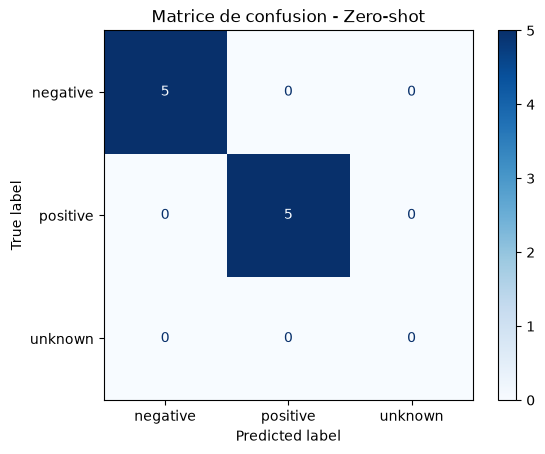

In [38]:
best_prompt_name = results_df["micro_f1"].idxmax()

best_details = prediction_details[best_prompt_name]

print("Prompt ayant le meilleur score :", best_prompt_name)

display(best_details)

labels = ["negative", "positive", "unknown"]

cm = confusion_matrix(
    best_details["sentiment_reel"],
    best_details["sentiment_predit"],
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap="Blues", values_format="d")
plt.title(f"Matrice de confusion - {best_prompt_name}")
plt.show()

In [39]:
num_eval_runs = 3  # Passer à 10 pour suivre exactement le PDF

few_shot_scores = []
cot_scores = []

for run in range(num_eval_runs):
    print(f"Répétition {run + 1}/{num_eval_runs}")

    # Tirer un nouvel échantillon d'exemples
    examples_run = create_examples(
        examples_df,
        n=n_shots,
        random_state=100 + run
    )

    # Reconstruire les deux prompts à partir des mêmes exemples
    few_shot_prompt_run = create_prompt(
        few_shot_system_message,
        examples_run,
        user_message_template
    )

    cot_prompt_run = create_prompt(
        cot_system_message,
        examples_run,
        user_message_template
    )

    # Évaluer séparément les deux prompts
    few_metrics, _ = evaluate_prompt(
        few_shot_prompt_run,
        gold_examples,
        user_message_template,
        llm2
    )

    cot_metrics, _ = evaluate_prompt(
        cot_prompt_run,
        gold_examples,
        user_message_template,
        llm2
    )

    few_shot_scores.append(few_metrics["micro_f1"])
    cot_scores.append(cot_metrics["micro_f1"])

    print(
        "Few-shot :", round(few_metrics["micro_f1"], 3),
        "| CoT :", round(cot_metrics["micro_f1"], 3)
    )


repeat_results = pd.DataFrame({
    "Répétition": range(1, num_eval_runs + 1),
    "Few-shot": few_shot_scores,
    "CoT Few-shot": cot_scores
})

display(repeat_results)

summary_results = pd.DataFrame({
    "Prompt": ["Few-shot", "CoT Few-shot"],
    "Moyenne micro-F1": [
        np.mean(few_shot_scores),
        np.mean(cot_scores)
    ],
    "Écart-type": [
        np.std(few_shot_scores),
        np.std(cot_scores)
    ]
})

display(summary_results.round(3))

Répétition 1/3
Few-shot : 1.0 | CoT : 1.0
Répétition 2/3
Few-shot : 1.0 | CoT : 1.0
Répétition 3/3
Few-shot : 1.0 | CoT : 1.0


,Répétition,Few-shot,CoT Few-shot
0,1,1.0,1.0
1,2,1.0,1.0
2,3,1.0,1.0


,Prompt,Moyenne micro-F1,Écart-type
0,Few-shot,1.0,0.0
1,CoT Few-shot,1.0,0.0


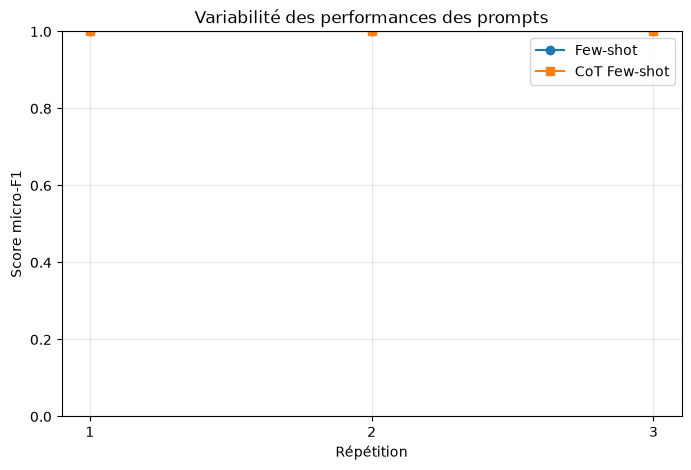

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, num_eval_runs + 1),
    few_shot_scores,
    marker="o",
    label="Few-shot"
)

plt.plot(
    range(1, num_eval_runs + 1),
    cot_scores,
    marker="s",
    label="CoT Few-shot"
)

plt.xlabel("Répétition")
plt.ylabel("Score micro-F1")
plt.title("Variabilité des performances des prompts")
plt.xticks(range(1, num_eval_runs + 1))
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()